# VizWiz Quality Gate Calibration Notebook

This notebook calibrates the three-metric on-device image quality gate described in the report, using the VizWiz-QualityIssues dataset.

## Pipeline Overview

| Cell | Description |
|---|---|
| 0 | Install dependencies |
| 1 | Download VizWiz-QualityIssues annotations and images |
| 2 | Blur threshold calibration script |
| 3 | Run blur threshold calibration |
| 4 | Display blur distribution plot |
| 5 | Threshold sweep table  |
| 6 | Blur detection trade-off curves |
| 7 | Multi-signal feature extraction |
| 8 | Blur-only vs multi-signal gate comparison  |
| 9 | Dark and bright threshold calibration |
| 10 | Overexposed pixel fraction threshold calibration |
| 11 | Combined gate performance evaluation |

## Outputs
- Figure 5 (Section 3.2.2.2) — Laplacian variance distribution for sharp vs blurry images
- Figure 7 (Section 4.2) — blur-only vs multi-signal gate ROC comparison
- Table 7 (Section 4.2) — combined gate performance
- Figure E.1 (Appendix E) — blur detection trade-off curves
- Table E.1 (Appendix E) — blur threshold sweep results

## Prerequisites
- Google Colab or local Python environment with GPU not required


## Cell 0: Install dependencies

Installs required packages for the quality gate calibration script: OpenCV (headless), NumPy, pandas, and matplotlib.



In [ ]:
!pip -q install opencv-python-headless numpy pandas matplotlib

## Cell 1: Download VizWiz-QualityIssues Dataset

Downloads and extracts the VizWiz-QualityIssues annotation file and VizWiz train/val images directly from the official Colorado source into Colab local disk:

- `/content/anns` — quality issue annotations (blur, dark, bright votes per image)
- `/content/images` — train and validation images


In [ ]:
!mkdir -p /content/images /content/anns

# Annotations
!wget -q --show-progress https://vizwiz.cs.colorado.edu/VizWiz_final/image_quality/annotations.zip -O /content/anns.zip
!unzip -q -o /content/anns.zip -d /content/anns

# Validation images
!wget -q --show-progress https://vizwiz.cs.colorado.edu/VizWiz_final/images/val.zip -O /content/val.zip
!unzip -q -o /content/val.zip -d /content/images

# Training images
!wget -q --show-progress https://vizwiz.cs.colorado.edu/VizWiz_final/images/train.zip -O /content/train.zip
!unzip -q -o /content/train.zip -d /content/images

print('Done. Files under /content/images and /content/anns')

/content/anns.zip   100%[===================>] 296.47K   408KB/s    in 0.7s    
/content/val.zip    100%[===================>]   3.25G  12.6MB/s    in 5m 7s   
/content/train.zip  100%[===================>]  10.52G  1.92MB/s    in 32m 31s 
Done. Files under /content/images and /content/anns


## Cell 2: Blur Threshold Calibration Script

Writes `calibrate_blur_threshold.py` to disk — the script used to calibrate the blur detection threshold against VizWiz-QualityIssues ground truth (Section 3.2.2.2):

- **Input:** VizWiz image folders and QualityIssues annotation JSON files
- **Labelling:** An image is labelled blurry if it receives ≥ `blur_votes` BLR annotations (default: 3/5 majority vote)
- **Preprocessing:** Each image is resized to 640px longest side and converted to grayscale — matching the on-device gate preprocessing
- **Threshold sweep:** Evaluates Laplacian variance thresholds across the 1st–90th percentile range, printing precision, recall, and F1 at each candidate value
- **Output:** `metrics.csv` (per-image Laplacian variance and label) and `blur_distribution.png` (Figure 5 in Section 3.2.2.2), with both the selected threshold (100) and F1-maximising threshold (140) marked

In [ ]:
%%writefile calibrate_blur_threshold.py

import argparse
import glob
import json
import os

import cv2
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

RESIZE_LONG_SIDE = 640


def load_labels(annotation_files, blur_votes):
    labels = {}
    for path in annotation_files:
        with open(path) as f:
            data = json.load(f)
        for entry in data:
            flaws = entry.get("flaws")
            if not flaws:
                continue
            name = entry["image"]
            labels[name] = 1 if flaws.get("BLR", 0) >= blur_votes else 0
    return labels


def compute_lap_var(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        return None
    h, w = img.shape[:2]
    scale = RESIZE_LONG_SIDE / max(h, w)
    if scale < 1.0:
        img = cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())


def find_images(image_dirs):
    found = {}
    for d in image_dirs:
        for ext in ("*.jpg", "*.jpeg", "*.png", "*.JPG"):
            for p in glob.glob(os.path.join(d, "**", ext), recursive=True):
                found[os.path.basename(p)] = p
    return found


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--images", nargs="+", required=True, help="folder(s) of VizWiz images")
    ap.add_argument("--annotations", nargs="+", required=True, help="VizWiz-QualityIssues JSON file(s)")
    ap.add_argument("--blur-votes", type=int, default=3, help="min BLR votes (0-5) to call an image blurry")
    ap.add_argument("--out", default="metrics.csv", help="where to save per-image metrics")
    args = ap.parse_args()

    labels = load_labels(args.annotations, args.blur_votes)
    print(f"Loaded {len(labels)} labelled images (BLR >= {args.blur_votes} => blurry).")

    files = find_images(args.images)
    print(f"Found {len(files)} image files in the given folders.")

    rows = []
    processed = 0
    for name, is_blurry in labels.items():
        path = files.get(name)
        if path is None:
            continue
        lv = compute_lap_var(path)
        if lv is None:
            continue
        rows.append({"filename": name, "lap_var": lv, "is_blurry": is_blurry})
        processed += 1
        if processed % 1000 == 0:
            print(f"  processed {processed} images...")

    df = pd.DataFrame(rows)
    if df.empty:
        print("No overlap between labelled images and image files. Check --images paths / filenames.")
        return

    sharp = df[df.is_blurry == 0].lap_var
    blur = df[df.is_blurry == 1].lap_var
    print(f"\n{len(df)} images matched: {len(sharp)} sharp, {len(blur)} blurry.")
    print(f"  sharp  lap_var: median {np.median(sharp):8.1f}")
    print(f"  blurry lap_var: median {np.median(blur):8.1f}")

    lo, hi = np.percentile(df.lap_var, 1), np.percentile(df.lap_var, 90)
    best = None
    print("\n  threshold   precision   recall     F1   (detecting blurry)")
    shown = set()
    for t in np.linspace(lo, hi, 80):
        pred = df.lap_var < t
        tp = int((pred & (df.is_blurry == 1)).sum())
        fp = int((pred & (df.is_blurry == 0)).sum())
        fn = int((~pred & (df.is_blurry == 1)).sum())
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
        if best is None or f1 > best[3]:
            best = (t, prec, rec, f1)
        b = round(t / 20) * 20
        if b not in shown:
            shown.add(b)
            print(f"  {t:8.1f}    {prec:7.3f}    {rec:7.3f}   {f1:6.3f}")

    t, prec, rec, f1 = best
    print(f"\n>>> Recommended kBlurThreshold = {t:.1f}   (precision {prec:.3f}, recall {rec:.3f}, F1 {f1:.3f})")

    plt.figure(figsize=(8, 5))
    cap = np.percentile(df.lap_var, 95)
    plt.hist(sharp, bins=60, alpha=0.6, label="sharp", color="#1D9E75", range=(0, cap))
    plt.hist(blur, bins=60, alpha=0.6, label="blurry", color="#D85A30", range=(0, cap))
    plt.axvline(100, color="black", linestyle="--", label="threshold 100 (selected)")
    plt.axvline(t, color="gray", linestyle=":", label=f"threshold {t:.0f} (F1-max)")
    plt.xlabel("Laplacian variance (sharpness)")
    plt.ylabel("Image count")
    plt.title(f"Sharp vs blurry (BLR >= {args.blur_votes})")
    plt.legend()
    plt.tight_layout()
    plt.savefig("blur_distribution.png", dpi=130)

    df.to_csv(args.out, index=False)
    print(f"\nSaved histogram -> blur_distribution.png")
    print(f"Saved per-image metrics -> {args.out}")


if __name__ == "__main__":
    main()


Overwriting calibrate_blur_threshold.py


## Cell 3: Run Blur Threshold Calibration

Executes `calibrate_blur_threshold.py` on the downloaded VizWiz images and QualityIssues annotations (excluding test set). Uses ≥3/5 majority vote as the blurry label criterion.

**Output:** `metrics.csv` and `blur_distribution.png`.

In [ ]:
import glob, os, subprocess

ann = [p for p in glob.glob('/content/anns/*.json')
       if 'test' not in os.path.basename(p).lower()]
print('Annotation files found:', ann)

cmd = ['python', 'calibrate_blur_threshold.py',
       '--images', '/content/images',
       '--annotations'] + ann + \
       ['--blur-votes', '3']
subprocess.run(cmd)

Annotation files found: ['/content/anns/val.json', '/content/anns/train.json']


CompletedProcess(args=['python', 'calibrate_blur_threshold.py', '--images', '/content/images', '--annotations', '/content/anns/val.json', '/content/anns/train.json', '--blur-votes', '3'], returncode=0)

## Cell 4: Display Blur Distribution Plot

Displays the Laplacian variance distribution histogram generated in Cell 3 (Figure 5 in Section 3.2.2.2).

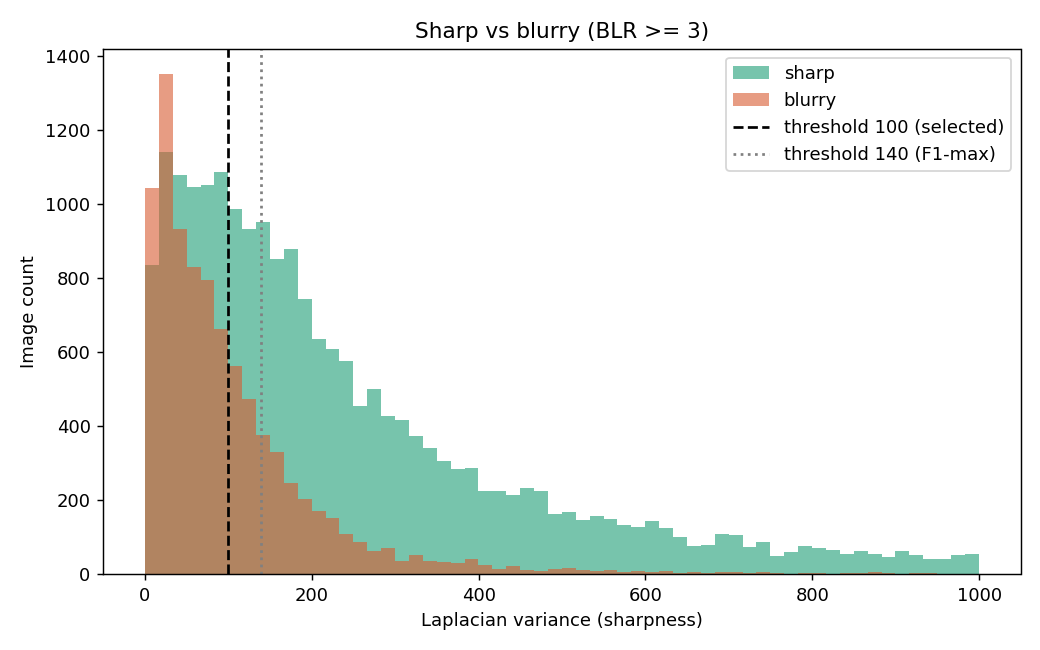

In [ ]:
from IPython.display import Image
Image('blur_distribution.png')

## Cell 5: Threshold Sweep Table

Computes precision, recall, F1, false rejection rate, and overall rejection rate for each candidate blur threshold against `metrics.csv`. Produces the data reported in Appendix E (Table E.1).

**Output:** Printed table and `threshold_table.csv`.

In [ ]:
import pandas as pd

THRESHOLDS = [60, 80, 100, 140, 180, 200, 250]

df = pd.read_csv('metrics.csv')
N_blur  = int((df.is_blurry == 1).sum())
N_sharp = int((df.is_blurry == 0).sum())
N_total = len(df)

rows = []
for T in THRESHOLDS:
    reject = df.lap_var < T
    tp = int((reject & (df.is_blurry == 1)).sum())
    fp = int((reject & (df.is_blurry == 0)).sum())
    fn = int((~reject & (df.is_blurry == 1)).sum())
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec  = tp / N_blur if N_blur else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    false_rej = fp / N_sharp if N_sharp else 0.0
    overall_rej = (tp + fp) / N_total
    rows.append({'threshold': T,
                 'blur_recall': round(rec, 3),
                 'blur_precision': round(prec, 3),
                 'F1': round(f1, 3),
                 'false_rejection_rate': round(false_rej, 3),
                 'overall_rejection_rate': round(overall_rej, 3)})

table = pd.DataFrame(rows)
print(f"Images: {N_total}  (blurry {N_blur}, sharp {N_sharp})\n")
print(table.to_string(index=False))
table.to_csv('threshold_table.csv', index=False)
print("\nSaved -> threshold_table.csv")

Images: 31181  (blurry 9014, sharp 22167)

 threshold  blur_recall  blur_precision    F1  false_rejection_rate  overall_rejection_rate
        60        0.424           0.510 0.463                 0.166                   0.241
        80        0.534           0.493 0.513                 0.223                   0.313
       100        0.623           0.474 0.538                 0.281                   0.380
       140        0.757           0.445 0.560                 0.385                   0.493
       180        0.839           0.415 0.555                 0.481                   0.584
       200        0.866           0.403 0.550                 0.522                   0.622
       250        0.913           0.381 0.537                 0.604                   0.694

Saved -> threshold_table.csv


## Cell 6: Blur Detection Trade-off Curves

Plots ROC-style trade-off curves for three annotator agreement levels (BLR ≥ 3, 4, 5), showing the relationship between blur recall and false rejection rate across the full threshold range. Produces Figure E.1 in Appendix E

**Output:** `tradeoff_curves.png`.

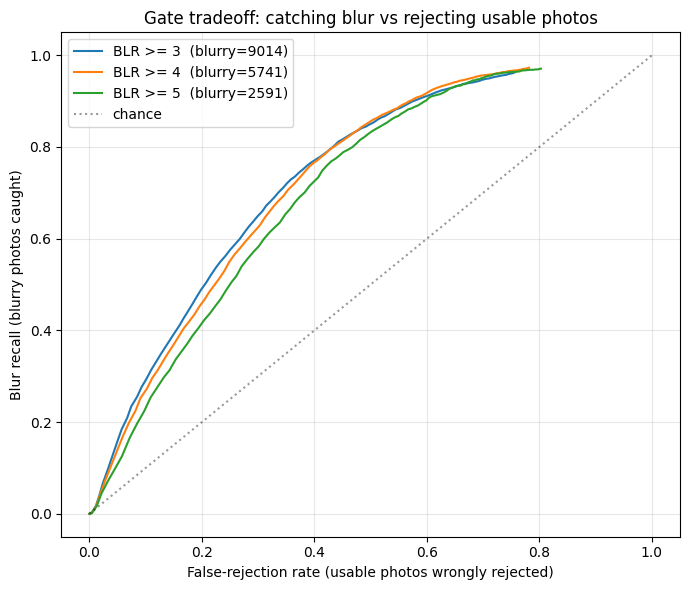

In [ ]:
import json, glob, os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt


m = pd.read_csv('metrics.csv')[['filename', 'lap_var']]


ann_files = [p for p in glob.glob('/content/anns/**/*.json', recursive=True)
             if 'test' not in os.path.basename(p).lower()]
recs = []
for path in ann_files:
    for e in json.load(open(path)):
        fl = e.get('flaws')
        if not fl:
            continue
        recs.append({'filename': e['image'], 'blr': fl.get('BLR', 0)})
b = pd.DataFrame(recs)
df = m.merge(b, on='filename', how='inner')


plt.figure(figsize=(7, 6))
for v in [3, 4, 5]:
    is_blur = (df.blr >= v).values
    N_blur, N_sharp = is_blur.sum(), (~is_blur).sum()
    ts = np.linspace(0, 400, 140)
    fr = [((df.lap_var.values < T) & ~is_blur).sum() / N_sharp for T in ts]
    rec = [((df.lap_var.values < T) & is_blur).sum() / N_blur for T in ts]
    plt.plot(fr, rec, label=f'BLR >= {v}  (blurry={N_blur})')

plt.plot([0, 1], [0, 1], 'k:', alpha=0.4, label='chance')
plt.xlabel('False-rejection rate (usable photos wrongly rejected)')
plt.ylabel('Blur recall (blurry photos caught)')
plt.title('Gate tradeoff: catching blur vs rejecting usable photos')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('tradeoff_curves.png', dpi=130)
plt.show()

## Cell 7: Multi-Signal Feature Extraction

Extracts five image quality features from all labelled VizWiz-QualityIssues images and saves them alongside per-flaw annotation votes:

- **Features:** Laplacian variance (blur), mean brightness, contrast (std), overexposed pixel fraction (>245), underexposed pixel fraction (<10)
- **Labels:** BLR, DRK, BRT, OBS, FRM, ROT, OTH, NON vote counts from annotations
- **Preprocessing:** Same 640px resize and grayscale conversion as the deployed gate

**Output:** `features.csv` — used in Cell 8 to compare blur-only vs multi-signal gate performance (Figure 7 in Section 4.2).

In [ ]:
import cv2, glob, os, json
import numpy as np, pandas as pd

RESIZE_LONG_SIDE = 640

def feats(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None: return None
    h, w = img.shape[:2]
    s = RESIZE_LONG_SIDE / max(h, w)
    if s < 1: img = cv2.resize(img, (int(w*s), int(h*s)), interpolation=cv2.INTER_AREA)
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return {'lap_var': float(cv2.Laplacian(g, cv2.CV_64F).var()),
            'brightness': float(g.mean()),
            'contrast': float(g.std()),
            'overexp': float((g > 245).mean()),
            'underexp': float((g < 10).mean())}


ann_files = [p for p in glob.glob('/content/anns/**/*.json', recursive=True)
             if 'test' not in os.path.basename(p).lower()]
lab = {}
for path in ann_files:
    for e in json.load(open(path)):
        fl = e.get('flaws')
        if fl: lab[e['image']] = fl

files = {}
for ext in ('*.jpg', '*.jpeg', '*.png'):
    for p in glob.glob(f'/content/images/**/{ext}', recursive=True):
        files[os.path.basename(p)] = p

rows, n = [], 0
for name, fl in lab.items():
    p = files.get(name)
    if not p: continue
    f = feats(p)
    if not f: continue
    f['filename'] = name
    for k in ('BLR','DRK','BRT','OBS','FRM','ROT','OTH','NON'):
        f[k.lower()] = fl.get(k, 0)
    rows.append(f); n += 1
    if n % 2000 == 0: print('processed', n)

pd.DataFrame(rows).to_csv('features.csv', index=False)
print('done', n, '-> features.csv')

processed 2000
processed 4000
processed 6000
processed 8000
processed 10000
processed 12000
processed 14000
processed 16000
processed 18000
processed 20000
processed 22000
processed 24000
processed 26000
processed 28000
processed 30000
done 31181 -> features.csv


## Cell 8: Blur-Only vs Multi-Signal Gate Comparison

Generates the ROC comparison between blur-only and multi-signal gate detection, producing Figure 7 in Section 4.2:

- **Label:** An image is "bad" if it receives ≥3 votes for blur, dark, or bright (OR logic)
- **Multi-signal proxy:** A logistic regression trained on five features generates the multi-signal ROC curve (used for visualisation only, not deployed)
- **Output:** `multisignal_curves.png`

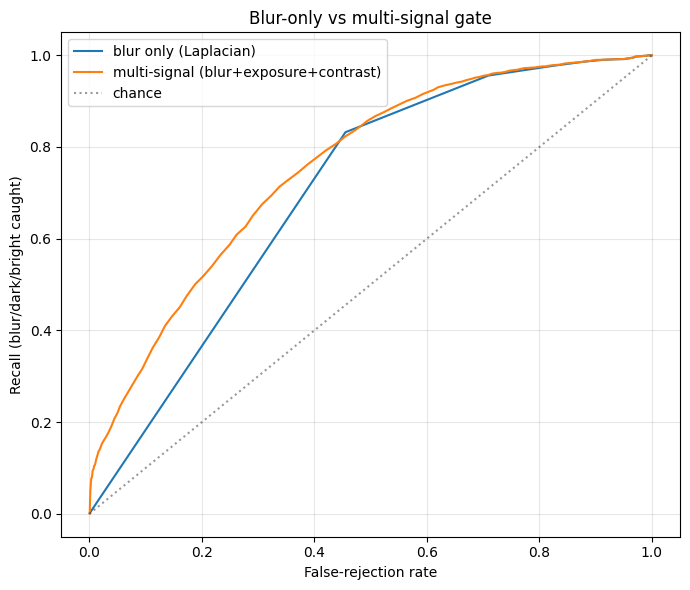

test set: 3009 bad, 6346 ok
feature weights (standardized, + => towards rejection):
  lap_var      -1.680
  contrast     -0.240
  underexp     +0.194
  overexp      +0.381
  bright_dev   +0.049


In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

df = pd.read_csv('features.csv')
VOTES = 3
df['bad'] = ((df.blr >= VOTES) | (df.drk >= VOTES) | (df.brt >= VOTES)).astype(int)
df['bright_dev'] = (df.brightness - 128).abs()
FEATURES = ['lap_var', 'contrast', 'underexp', 'overexp', 'bright_dev']

tr, te = train_test_split(df, test_size=0.3, random_state=0, stratify=df.bad)
sc = StandardScaler().fit(tr[FEATURES])
lr = LogisticRegression(max_iter=1000, class_weight='balanced').fit(sc.transform(tr[FEATURES]), tr.bad)
te = te.copy()
te['score'] = lr.predict_proba(sc.transform(te[FEATURES]))[:, 1]
N_bad, N_ok = int((te.bad == 1).sum()), int((te.bad == 0).sum())

def curve(scores):
    qs = np.linspace(scores.min(), scores.max(), 200); fr = []; rec = []
    for q in qs:
        rej = scores >= q
        fr.append((rej & (te.bad == 0).values).sum() / N_ok)
        rec.append((rej & (te.bad == 1).values).sum() / N_bad)
    return fr, rec

fr_m, rec_m = curve(te.score.values)
fr_b, rec_b = curve(-te.lap_var.values)
plt.figure(figsize=(7, 6))
plt.plot(fr_b, rec_b, label='blur only (Laplacian)')
plt.plot(fr_m, rec_m, label='multi-signal (blur+exposure+contrast)')
plt.plot([0, 1], [0, 1], 'k:', alpha=0.4, label='chance')
plt.xlabel('False-rejection rate'); plt.ylabel('Recall (blur/dark/bright caught)')
plt.title('Blur-only vs multi-signal gate'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('multisignal_curves.png', dpi=130); plt.show()

print(f'test set: {N_bad} bad, {N_ok} ok')
print('feature weights (standardized, + => towards rejection):')
for f, c in zip(FEATURES, lr.coef_[0]): print(f'  {f:12s} {c:+.3f}')

## Cell 9: Dark and Bright Threshold Calibration

Sweeps brightness thresholds for dark and overexposed image detection, identifying the F1-maximising value for each metric against VizWiz-QualityIssues ground truth (Section 3.2.2.2):

- **Dark:** Mean brightness < threshold (low direction)
- **Bright:** Mean brightness > threshold (high direction)

**Output:** Optimal threshold, precision, recall, and F1 for each metric — used to set `dark_threshold` and `bright_threshold` in CONFIG.

In [ ]:
import pandas as pd, numpy as np

df = pd.read_csv('features.csv')
VOTES = 3

def sweep(col, direction):

    label = (df[col] >= VOTES).values
    lo, hi = np.percentile(df.brightness, 1), np.percentile(df.brightness, 99)
    best = None
    for T in np.linspace(lo, hi, 300):
        pred = (df.brightness.values < T) if direction == 'low' else (df.brightness.values > T)
        tp = (pred & label).sum(); fp = (pred & ~label).sum(); fn = (~pred & label).sum()
        prec = tp/(tp+fp) if (tp+fp) else 0
        rec  = tp/(tp+fn) if (tp+fn) else 0
        f1   = 2*prec*rec/(prec+rec) if (prec+rec) else 0
        if best is None or f1 > best[3]:
            best = (T, prec, rec, f1)
    return best

# Dictionary to store results
threshold_results = {}
for col, dirn, name in [('drk', 'low', 'DARK (kDarkThreshold)'),
                        ('brt', 'high', 'BRIGHT')]:
    T, prec, rec, f1 = sweep(col, dirn)
    threshold_results[name] = {'threshold': T, 'precision': prec, 'recall': rec, 'f1': f1}
    print(f"Optimal threshold for {name}: T={T:.1f}, Precision={prec:.3f}, Recall={rec:.3f}, F1={f1:.3f})")

# Display all results
print("\nSummary of optimal thresholds:")
for name, res in threshold_results.items():
    print(f"  {name}: Threshold={res['threshold']:.1f}, F1={res['f1']:.3f}")

Optimal threshold for DARK (kDarkThreshold): T=34.0, Precision=0.796, Recall=0.596, F1=0.682)
Optimal threshold for BRIGHT: T=187.0, Precision=0.483, Recall=0.249, F1=0.328)

Summary of optimal thresholds:
  DARK (kDarkThreshold): Threshold=34.0, F1=0.682
  BRIGHT: Threshold=187.0, F1=0.328


## Cell 10: Overexposed Pixel Fraction Threshold Calibration

Calibrates the overexposure threshold using pixel saturation fraction (`overexp`) rather than mean brightness, as described in Section 3.2.2.2:

- Sweeps the overexposed pixel fraction threshold across the 50th–99.5th percentile range
- Compares against the brightness-based bright detector to confirm that pixel fraction outperforms mean brightness for overexposure detection

**Output:** Optimal `overexp` threshold — used as `bright_threshold` in CONFIG.

In [ ]:
import pandas as pd, numpy as np

df = pd.read_csv('features.csv')
VOTES = 3
label = (df.brt >= VOTES).values
n = int(label.sum())

lo, hi = np.percentile(df.overexp, 50), np.percentile(df.overexp, 99.5)
best = None
for T in np.linspace(lo, hi, 300):
    pred = df.overexp.values > T
    tp = (pred & label).sum(); fp = (pred & ~label).sum(); fn = (~pred & label).sum()
    prec = tp/(tp+fp) if (tp+fp) else 0
    rec  = tp/(tp+fn) if (tp+fn) else 0
    f1   = 2*prec*rec/(prec+rec) if (prec+rec) else 0
    if best is None or f1 > best[3]:
        best = (T, prec, rec, f1)

T, prec, rec, f1 = best
print(f'BRIGHT via overexp: n={n}  threshold(overexp)={T:.4f}  P={prec:.2f} R={rec:.2f} F1={f1:.2f}')
print(f'(compare: brightness-based BRIGHT F1 was ~0.33)')

BRIGHT via overexp: n=727  threshold(overexp)=0.2312  P=0.38 R=0.35 F1=0.37
(compare: brightness-based BRIGHT F1 was ~0.33)


In [ ]:
import pandas as pd
df = pd.read_csv('metrics.csv')
low  = df[df.lap_var < 40].sample(2, random_state=1)
high = df[df.lap_var > 300].sample(2, random_state=1)
print(pd.concat([low, high])[['filename','lap_var']].to_string(index=False))

                 filename    lap_var
  VizWiz_val_00000006.jpg  31.000902
VizWiz_train_00018703.jpg  35.259024
VizWiz_train_00009491.jpg 596.559641
VizWiz_train_00006192.jpg 679.566937


In [ ]:
from google.colab import files
for name in ['VizWiz_val_00000006.jpg','VizWiz_train_00018703.jpg',
             'VizWiz_train_00009491.jpg','VizWiz_train_00006192.jpg']:
    import glob
    p = glob.glob(f'/content/images/**/{name}', recursive=True)

## Cell 11: Combined Gate Performance Evaluation

Evaluates the full three-metric quality gate (blur OR dark OR bright) against VizWiz-QualityIssues ground truth using the calibrated thresholds, producing the results reported in Table 7 (Section 4.2):

- **Thresholds:** Laplacian variance < 100 (blur), mean brightness < 34.0 (dark), overexposed pixel fraction > 0.2312 (bright)
- **OR logic:** An image is rejected if any single check fails
- **Metrics:** Precision, recall, F1, false rejection rate, and overall rejection rate

**Output:** Combined gate performance figures used in Table 7.

In [ ]:
import pandas as pd

df = pd.read_csv('features.csv')
VOTES = 3


df['bad'] = ((df.blr >= VOTES) | (df.drk >= VOTES) | (df.brt >= VOTES)).astype(int)


df['gate_reject'] = (
    (df.lap_var < 100) |          # blur
    (df.brightness < 34.0) |      # dark
    (df.overexp > 0.2312)         # bright
).astype(int)

tp = int(((df.gate_reject == 1) & (df.bad == 1)).sum())
fp = int(((df.gate_reject == 1) & (df.bad == 0)).sum())
fn = int(((df.gate_reject == 0) & (df.bad == 1)).sum())
tn = int(((df.gate_reject == 0) & (df.bad == 0)).sum())

precision = tp / (tp + fp) if (tp + fp) else 0
recall = tp / (tp + fn) if (tp + fn) else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0
false_rejection_rate = fp / (tn + fp) if (tn + fp) else 0
overall_rejection_rate = (tp + fp) / len(df)

print(f"Combined gate — N={len(df)}  bad={int(df.bad.sum())}  ok={len(df)-int(df.bad.sum())}")
print(f"Precision={precision:.3f}  Recall={recall:.3f}  F1={f1:.3f}")
print(f"False rejection rate={false_rejection_rate:.3f}  Overall rejection rate={overall_rejection_rate:.3f}")

Combined gate — N=31181  bad=10029  ok=21152
Precision=0.529  Recall=0.640  F1=0.580
False rejection rate=0.270  Overall rejection rate=0.389
